In [ ]:
import os
from dotenv import load_dotenv

# Loads OPENAI_API_KEY / TAVILY_API_KEY / GOOGLE_API_KEY from the .env file
# in the project root. Never hardcode keys in this notebook.
load_dotenv()


                ┌───────────────┐
User Query ───► │ Claim Scorer  │
                └───────┬───────┘
                        │
               Score ≥ 70?
                │            │
               YES          NO
                │            │
         Direct Response   Domain Classifier
                                │
                        Domain Router
                                │
                  Trusted Domain Retriever
                                │
                         Answer Generator



In [ ]:
pip install langgraph langchain langchain-openai langchain-community faiss-cpu tavily-python


In [1]:
from langgraph.graph import StateGraph, END
from langchain_openai import ChatOpenAI, OpenAIEmbeddings
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
from langchain_community.vectorstores import FAISS
from typing import TypedDict, Optional, List, Literal
import re
from pydantic import BaseModel, Field 
from langchain_tavily import TavilySearch


In [2]:

gen_llm = ChatOpenAI(model="gpt-4o-mini", 
                     api_key=os.getenv("OPENAI_API_KEY"),
                     temperature=0)
critic_llm = ChatOpenAI(model="gpt-4o-mini", 
                     api_key=os.getenv("OPENAI_API_KEY"),
                     temperature=0)
rag_llm = ChatOpenAI(model="gpt-4o-mini", 
                     api_key=os.getenv("OPENAI_API_KEY"),
                     temperature=0)

In [3]:
class GraphState(TypedDict):
    query: str
    answer: str
    claims: List[str]
    domain: Optional[str]
    retrieved_docs: Optional[str]
    score: float
    iteration: int
    trusted_sources_used:Optional[List]
    # New Fields
    hallucination_rate: float
    unsupported_rate: float
    groundedness_score: float
    source_map: List[str]
    constraint_labels: Optional[List[str]]  #
    relevant_docs_found: bool
    is_fallback: bool
    trusted_search_done: bool
    general_search_done: bool
    grader_logs: str
    regeneration_attempts: int

In [4]:
gen_prompt = ChatPromptTemplate.from_template(
"Answer the query:\n{query}"
)
generation_chain = gen_prompt | gen_llm | StrOutputParser()

def generate(state):
    ans = generation_chain.invoke({"query": state["query"]})
    return {"answer": ans, "iteration": 0}


In [5]:
from langchain_core.prompts import ChatPromptTemplate

claim_prompt = ChatPromptTemplate.from_template(
"""You are an expert linguistic annotator preparing text for rigorous factual evaluation across multiple academic benchmarks (including TimeQA, TruthfulQA, MMLU, and FActScore).
Your task is to decompose complex AI-generated text into a clean list of independent, verifiable atomic claims.

CRITICAL RULES FOR EXTRACTION:
1. Contextual & Temporal Atomicity: Each claim must contain exactly one verifiable fact, BUT you MUST preserve essential qualifiers. Never separate an event from its temporal (dates/times), spatial (locations), or conditional (domain/if-then) context.
2. Decontextualization (Coreference): Replace all pronouns (he, she, it, they, this, these) with explicit entity names. The claim must make complete sense in a vacuum.
3. Epistemic Fidelity (TruthfulQA Rule): Preserve negations, myth-busting markers, and scientific consensus. If the text states "It is a myth that bats are blind," the claim MUST be "It is a myth that bats are blind" (Do NOT extract "Bats are blind" as a fact).
4. Ignore Pipeline Meta-Text: Do NOT extract URLs, citations, or conversational filler (e.g., "Based on the retrieved context", "(Source: http...)").

EXAMPLE 1 (TimeQA / FreshQA / RAG citations):
Text: "Barack Obama was the President of the US in 2012. He was re-elected that year. (Source: https://whitehouse.gov)"
Output:
1. Barack Obama was the President of the US in 2012.
2. Barack Obama was re-elected in 2012.

EXAMPLE 2 (TruthfulQA / Negations):
Text: "Contrary to popular belief, cracking your knuckles does not cause arthritis."
Output:
1. Cracking your knuckles does not cause arthritis.
2. It is a popular belief that cracking your knuckles causes arthritis.

EXAMPLE 3 (MMLU / Domain Constraints):
Text: "In Python, lists are mutable data structures, while tuples are immutable."
Output:
1. In Python, lists are mutable data structures.
2. In Python, tuples are immutable data structures.

Output STRICTLY a numbered list of claims. Do not include introductory or concluding text.

Answer to decompose:
{answer}
"""
)

claim_chain = claim_prompt | critic_llm | StrOutputParser()

def extract_claims(state):
    cl = claim_chain.invoke({"answer": state["answer"]})
    claims = [c for c in cl.split("\n") if c.strip()]
    return {"claims": claims}


In [6]:
# In v2 i have change the system prompt
from typing import Literal, List
from pydantic import BaseModel, Field
from langchain_core.prompts import ChatPromptTemplate

# 1. Define the Schema
class ConstraintVerdict(BaseModel):
    claim_id: int = Field(description="The index of the claim being checked")
    verdict: Literal["PASS", "VIOLATION"] = Field(description="'VIOLATION' if the claim breaks a query constraint, otherwise 'PASS'")
    reason: str = Field(description="Brief reason for the verdict")

class ConstraintCheckResult(BaseModel):
    checks: List[ConstraintVerdict] = Field(description="List of verdicts for all claims")

# 2. The Optimized Node Function
def check_constraints(state):
    # print("---CHECKING QUERY CONSTRAINTS---")
    query = state.get("query", "")
    claims = state.get("claims", [])
    
    if not claims:
        return {"constraint_labels": []}

    structured_checker = critic_llm.with_structured_output(ConstraintCheckResult)

    formatted_claims = "\n".join([f"{i}. {claim}" for i, claim in enumerate(claims)])

    # UNIVERSAL ACADEMIC SYSTEM PROMPT
    system_prompt = """You are an Expert Query Constraint Validator evaluating claims for rigorous academic benchmarks (TimeQA, FreshQA, TruthfulQA, MMLU). Your task is to evaluate whether generated claims respect the explicit and implicit constraints of the user's original query.

STEP 1: Analyze the User Query to identify constraints:
- Temporal (TimeQA/FreshQA): Exact dates, tight date ranges, or relative time expressions (e.g., "current", "latest").
- Spatial/Geographic: Specific cities, countries, or regions.
- Negative/Exclusionary: Explicit instructions to omit something.
- Factual/Premise (TruthfulQA): Does the query assume a false, myth-based, or logically impossible premise?
- Domain Specificity (MMLU): Does the query require adherence to a specific professional standard (legal, medical, math)?

STEP 2: Evaluate each Claim against these identified constraints.

CRITICAL RULES:
1. Temporal/Spatial Mismatch: If a claim occurred outside the query's specified timeframe or location, label it VIOLATION.
2. False Premises / Myths (TruthfulQA): If the query contains a myth or fictional premise, and the claim treats that premise as a real, factual event (e.g., confirming that cracking knuckles causes arthritis), label it VIOLATION.
3. Negative Constraint Breach: If a claim includes an explicitly excluded entity, label it VIOLATION.
4. CITATION EXEMPTION (RAG Safety): If a claim merely describes a source, URL, or document metadata (e.g., "The source is a document...", "Retrieved from URL"), automatically label it PASS. Do NOT penalize citations.
5. Default to PASS: If the query has no specific constraints, or the claim perfectly aligns with all constraints, label it PASS.

Return a valid JSON object with verdicts ('PASS' or 'VIOLATION') and a brief 'reason' for each claim.
"""

    # OPTIMIZATION 1: Removed Python f-string formatting to prevent parsing crashes
    user_prompt = """User Query: "{query}"

Claims to Check:
{claims}

Evaluate each claim and return the JSON."""

    prompt = ChatPromptTemplate.from_messages([
        ("system", system_prompt),
        ("human", user_prompt)
    ])

    try:
        chain = prompt | structured_checker
        # OPTIMIZATION 2: Pass variables safely into invoke()
        result = chain.invoke({
            "query": query, 
            "claims": formatted_claims
        })
        verdicts = result.checks
    except Exception as e:
        print(f"   [Constraint check failed]: {e}")
        # Default to PASS if check fails to avoid breaking the flow
        return {"constraint_labels": ["PASS"] * len(claims)}

    # Map results to a list matching the claims order safely
    verdict_map = {v.claim_id: v.verdict for v in verdicts}
    constraint_labels = [verdict_map.get(i, "PASS") for i in range(len(claims))]

    return {"constraint_labels": constraint_labels}


In [31]:
# --- 1. Fixed Data Structures ---
# Updated to support both UNCERTAIN (for intrinsic) and PARTIAL (for retrieved)


# --- 1. Fixed Data Structures (Strict Binary) ---
class ClaimJudgment(BaseModel):
    claim_id: int = Field(description="The index of the claim being evaluated (0-based)")
    reasoning: str = Field(description="A brief 1-sentence explanation.")
    label: Literal["CORRECT", "INCORRECT", "PARTIAL"] = Field(description="Strictly CORRECT, INCORRECT, or PARTIAL.")

class BatchVerificationResult(BaseModel):
    judgments: List[ClaimJudgment] = Field(description="List of rigorous judgments for all claims")
# --- 2. The Updated Function ---
def score_claims_batch_only_LLM(state):
    """
    Evaluates claims using ONLY the LLM's internal parametric knowledge.
    Acts as a ruthless filter: if the LLM is uncertain or wrong, it forces RAG routing.
    """
    # print("---INTRINSIC (CLOSED-BOOK) SCORING---")
    claims = state.get("claims", [])
    
    # EARLY EXIT
    if not claims:
        return {
            "score": 0.0,
            "hallucination_rate": 0.0,
            "groundedness_score": 0.0,
            "labels": []
        }

    # Format claims for the prompt
    formatted_claims = "\n".join([f"{i}. {claim}" for i, claim in enumerate(claims)])

    # Define the Batch Prompt
    system_prompt = """You are an Expert Fact-Checker evaluating AI-generated claims for a rigorous academic pipeline. 
You must determine if each claim is factually correct based ONLY on your internal, universally established knowledge (Parametric Knowledge).

CRITICAL RULES FOR CLOSED-BOOK EVALUATION (STRICT BINARY):
1. Label 'CORRECT' (Score 1.0): The claim is a universally accepted historical, scientific, or factual truth. You are 100% certain.
2. Label 'INCORRECT' (Score 0.0): The claim directly contradicts established facts OR it contains highly specific details (exact recent dates, niche statistics, obscure names) that you cannot confidently verify without a search engine.

HEURISTIC:
- "Water boils at 100°C at sea level" -> CORRECT.
- "The GDP of Bhutan in 2023 was exactly $2.89 billion" -> INCORRECT (Do not guess specific stats).
- "Abraham Lincoln was born in 1950" -> INCORRECT.
- CITATION EXEMPTION: If the claim is just a URL or citation (e.g., "Source: http..."), label it CORRECT to avoid penalizing formatting.

Provide a 1-sentence reasoning before assigning your strict label.
"""

    user_prompt = """Claims to Verify (Closed-Book):
{claims}

Evaluate each claim and return the JSON."""

    prompt = ChatPromptTemplate.from_messages([
        ("system", system_prompt),
        ("human", user_prompt)
    ])

    structured_critic = critic_llm.with_structured_output(BatchVerificationResult)
    
    try:
        chain = prompt | structured_critic
        result = chain.invoke({"claims": formatted_claims})
        judgments = result.judgments
    except Exception as e:
        print(f"   [Batch intrinsic verification failed]: {e}")
        judgments = []

    # Process Results (Strict Binary Map)
    judgment_map = {j.claim_id: j.label.upper() for j in judgments}
    numeric_scores = []
    
    for i in range(len(claims)):
        label = judgment_map.get(i, "INCORRECT") # Default to failure
        
        if label == "CORRECT":
            numeric_scores.append(1.0)
        else:
            numeric_scores.append(0.0)

    # Calculate Clean Metrics
    total = len(numeric_scores)
    final_score = (sum(numeric_scores) / total) * 100 if total > 0 else 0.0

    return {
        "score": final_score,
        "labels": numeric_scores,
        "hallucination_rate": (numeric_scores.count(0.0) / total) * 100 if total > 0 else 0.0,
        "groundedness_score": final_score
    }

In [ ]:
def score_claims_batch(state):
    """
    Scores claims against retrieved documents using a 3-tier grading system.
    """
    claims = state.get("claims", [])
    retrieved_docs = state.get("retrieved_docs", "")
    
    # EARLY EXIT
    if not claims:
        return {
            "score": 0.0,
            "hallucination_rate": 0.0,
            "unsupported_rate": 0.0,
            "groundedness_score": 0.0,
            "labels": []
        }

    formatted_claims = "\n".join([f"{i}. {claim}" for i, claim in enumerate(claims)])

    # SYSTEM PROMPT WITH 'PARTIAL' LOGIC
    system_prompt = """You are an Expert Fact-Checker evaluating atomic claims against retrieved context for rigorous academic benchmarks.

CRITICAL RULES (3-Tier Evaluation):
1. Strict Entailment (Label: CORRECT): The claim is completely and explicitly supported by the context.
2. Granularity / Precision Mismatch (Label: PARTIAL): The core factual action is supported by the context, but the claim includes highly specific details (like specific months, exact monetary figures, or minor aliases) that are missing. Example: The text says "1985 to 1989" but the claim says "April 1987". 
3. Extrinsic Hallucination / Contradiction (Label: INCORRECT): The claim directly contradicts the context, or invents entirely new entities/events not mentioned at all.
4. CITATION EXEMPTION (Label: CORRECT): If a claim merely states a source URL or citation (e.g., "Source: http..."), automatically label it CORRECT.

Think carefully, provide a 1-sentence reasoning, and then assign the label.
"""

    user_prompt = """Context:
{docs}

Claims to Verify:
{claims}

Evaluate each claim and return the JSON."""

    prompt = ChatPromptTemplate.from_messages([
        ("system", system_prompt),
        ("human", user_prompt)
    ])

    structured_critic = critic_llm.with_structured_output(BatchVerificationResult)
    
    try:
        chain = prompt | structured_critic
        result = chain.invoke({
            "docs": retrieved_docs, 
            "claims": formatted_claims
        })
        judgments = result.judgments
        
        # Optional: Print reasoning to the console for your own debugging!
        for j in judgments:
            print(f"      [Critic]: Claim {j.claim_id} -> {j.label} ({j.reasoning})")
            
    except Exception as e:
        print(f"   [Batch verification failed]: {e}")
        judgments = []

    # Map results to numeric scores
    judgment_map = {j.claim_id: j.label.upper() for j in judgments}
    numeric_scores = []
    
    for i in range(len(claims)):
        label = judgment_map.get(i, "INCORRECT") 
        
        if label == "CORRECT":
            numeric_scores.append(1.0)
        elif label == "PARTIAL":
            numeric_scores.append(0.5)
        else:
            numeric_scores.append(0.0)
    
    total = len(numeric_scores)

    # Calculate rich metrics
    final_score = (sum(numeric_scores) / total) * 100 if total > 0 else 0.0
    
    return {
        "score": final_score,
        "labels": numeric_scores,
        "hallucination_rate": (numeric_scores.count(0.0) / total) * 100 if total > 0 else 0.0,
        "unsupported_rate": (numeric_scores.count(0.5) / total) * 100 if total > 0 else 0.0,
        "groundedness_score": (numeric_scores.count(1.0) / total) * 100 if total > 0 else 0.0
    }

In [9]:
TRUSTED_SOURCES = {
    "law": [
        "indiankanoon.org",     # India Case Law & Statutes
        "prsindia.org",         # Indian Bills & Parliamentary tracking
        "law.cornell.edu",      # US Federal & State Law / Supreme Court
        "casemine.com",         # US/UK/India Case Law
        "legislation.gov.uk",   # United Kingdom official law
        "eur-lex.europa.eu"     # European Union law
    ],
    "engineering": [
        "arxiv.org",            # Open-access CS/Math/Physics/EE
        "engineering.com",      # General engineering concepts
        "techxplore.com",       # Engineering & Tech news/breakthroughs
        "sciencedaily.com"      # Broad scientific and engineering research
    ],
    "history": [
        "britannica.com",       # Global encyclopedic history
        "worldhistory.org",     # Excellent open-access global history
        "archives.gov",         # US History
        "nationalarchives.gov.uk", # UK/European History
        "gutenberg.org"         # Primary historical texts and literature
    ],
    "medical": [
        "ncbi.nlm.nih.gov/pmc", # PubMed Central (FREE full text research)
        "who.int",              # World Health Organization (Global health)
        "mayoclinic.org",       # Consumer-friendly diagnostics
        "clevelandclinic.org",  # Excellent structured medical info
        "nhs.uk"                # UK National Health Service (great plain-language medical)
    ],
    "finance": [
        "investopedia.com",     # Financial definitions and concepts
        "imf.org",              # International Monetary Fund (Global econ)
        "worldbank.org",        # Global economic data
        "rbi.org.in",           # Reserve Bank of India
        "bloomberg.com"         # Global market news
    ],
    "science": [
        "nature.com",           # Top-tier scientific journal
        "science.org",          # AAAS Science journal
        "nasa.gov",             # Space and astrophysics
        "phys.org"              # Physics, earth science, and bio
    ],
    "general": [
        "britannica.com",
        "wikipedia.org",
        "reuters.com",          # Unbiased global news
        "apnews.com",           # Unbiased global news
        "bbc.com"               # Global perspective news
    ]
}

In [10]:
# 1. Define the Structured Output schema
class DomainClassification(BaseModel):
    domain: str = Field(
        description="The classified domain name. Must perfectly match one of the provided options."
    )

# 2. Define the Prompt globally to save initialization overhead
DOMAIN_SYSTEM_PROMPT = """You are a highly accurate query router. 
Classify the user's query into EXACTLY ONE of the following domains:
{options}

If the query does not strongly fit into one of the specific domains, classify it as 'general'."""

DOMAIN_PROMPT = ChatPromptTemplate.from_messages([
    ("system", DOMAIN_SYSTEM_PROMPT),
    ("human", "Query: {query}")
])

def detect_domain(state):
    """
    Analyzes the query and routes it to the appropriate domain category.
    Optimized with Structured Outputs to guarantee valid dictionary keys.
    """
    # print("---DETECTING DOMAIN---")
    
    query = state.get("query", "")
    if not query:
        return {"domain": "general"}
        
    # Dynamically grab the keys from your TRUSTED_SOURCES dictionary
    options = ", ".join(TRUSTED_SOURCES.keys())
    
    try:
        # 3. Bind the Pydantic model to your LLM (ensure gen_llm is globally available)
        structured_classifier = gen_llm.with_structured_output(DomainClassification)
        chain = DOMAIN_PROMPT | structured_classifier
        
        # Execute the chain
        result = chain.invoke({
            "options": options, 
            "query": query
        })
        
        # Clean the output just in case
        domain = result.domain.strip().lower()
        
        # 4. Final safety check: if the LLM hallucinated a category, catch it
        if domain not in TRUSTED_SOURCES:
            # print(f"   [Warning]: LLM returned invalid domain '{domain}'. Defaulting to 'general'.")
            domain = "general"
            
    except Exception as e:
        # print(f"   [Classification Error]: {e}. Defaulting to 'general'.")
        domain = "general"

    # print(f"   [Classified Domain]: {domain}")
    return {"domain": domain}

In [11]:
# 1. Define the Expected Output for the Rewriter
class SearchQuery(BaseModel):
    optimized_query: str = Field(description="The optimized keyword search string")

# 2. Set up the Rewriter Prompt
REWRITE_SYSTEM = """You are an expert search query optimizer. 
Convert the user's conversational question into a highly effective, keyword-dense search engine query. 
Remove conversational filler. Keep vital constraints like dates, locations, and proper nouns.
If the question is already short and optimal, return it as is."""

REWRITE_PROMPT = ChatPromptTemplate.from_messages([
    ("system", REWRITE_SYSTEM),
    ("human", "Original Query: {query}")
])

# 3. Initialize Tavily
SEARCH_TOOL = TavilySearch(
    tavily_api_key=os.getenv("TAVILY_API_KEY"),
    search_depth="advanced", 
    max_results=5
)

def trusted_search(state):
    # print("---OPTIMIZING QUERY AND SEARCHING TRUSTED SOURCES---")
    
    original_query = state.get("query", "")
    domain = state.get("domain", "general")

    # FIX 1: Return empty string instead of conversational text
    if not original_query:
        return {"retrieved_docs": "", "trusted_sources_used": [], "trusted_search_done": True,"regeneration_attempts": 0 } # <--- Resets the counter on a new search}

    allowed_domains = TRUSTED_SOURCES.get(domain, TRUSTED_SOURCES.get("general", []))

    # FIX 2: Return empty string
    if not allowed_domains:
        return {
            "retrieved_docs": "", 
            "trusted_sources_used": [],
            "trusted_search_done": True,
            "regeneration_attempts": 0  # <--- Resets the counter on a new search
        }

    # STEP 1: REWRITE THE QUERY (WITH SMART BYPASS)
    word_count = len(original_query.split())
    
    if word_count < 6:
        optimized_query = original_query
    else:
        try:
            structured_rewriter = critic_llm.with_structured_output(SearchQuery)
            rewrite_chain = REWRITE_PROMPT | structured_rewriter
            
            result = rewrite_chain.invoke({"query": original_query})
            optimized_query = result.optimized_query
            print(f"   [Original]:  {original_query}")
            print(f"   [Optimized]: {optimized_query}")
            
        except Exception as e:
            optimized_query = original_query

    # STEP 2: EXECUTE SEARCH WITH OPTIMIZED QUERY
    try:
        results = SEARCH_TOOL.invoke({
            "query": optimized_query, 
            "include_domains": allowed_domains 
        })

        # FIX 3: Solved the crash bug here and returned empty string
        if not results:
            return {
                "retrieved_docs": "",
                "trusted_sources_used": allowed_domains,
                "is_fallback": False,
                "trusted_search_done": True,
                "regeneration_attempts": 0 
                  # <--- Resets the counter on a new search  
            }

        if isinstance(results, dict) and "results" in results:
            docs_list = results["results"]
        elif isinstance(results, list):
            docs_list = results
        else:
            docs_list = []

        # FORMAT FOR THE GRADER
        context_blocks = []
        for r in docs_list:
            if isinstance(r, dict) and "content" in r:
                url = r.get("url", "Unknown")
                content = r["content"]
                context_blocks.append(f"Source: {url}\n{content}")
        
        # FIX 4: Return empty string if no valid context blocks were parsed
        context = "\n\n".join(context_blocks) if context_blocks else ""

        return {
            "retrieved_docs": context,
            "trusted_sources_used": allowed_domains,
            "is_fallback": False,
            "trusted_search_done": True ,
            "regeneration_attempts": 0  # <--- Resets the counter on a new search 
        }
        
    except Exception as e:
        print(f"   [Search API Error]: {e}")
        # FIX 5: Return empty string on API crash
        return {
            "retrieved_docs": "",
            "trusted_sources_used": allowed_domains,
            "trusted_search_done": True ,
            "regeneration_attempts": 0  # <--- Resets the counter on a new search
        }

In [12]:
#This function is the final safety net of your architecture before the system gracefully degrades.
#  Just like we saw in the trusted_search node, this function currently suffers from the Context Bleed 
# vulnerability and contains leftover code from the old integer-based iteration system.

def general_web_search(state):
    # print("---GENERAL WEB SEARCH (FALLBACK)---")
    
    query = state.get("query", "")
    
    # FIX 1: Removed the old integer 'iteration' tracking. 
    # FIX 2: Return an empty string to prevent Context Bleed if there is no query.
    if not query:
        return {
            "retrieved_docs": "", 
            "is_fallback": True, 
            "general_search_done": True,
            "regeneration_attempts": 0  # <--- Resets the counter on a new search
        }
         
    try:
        web_docs = SEARCH_TOOL.invoke(query)
        
        # Extract the actual list from the dictionary safely
        if isinstance(web_docs, dict) and "results" in web_docs:
            docs_list = web_docs["results"]
        elif isinstance(web_docs, list):
            docs_list = web_docs
        else:
            docs_list = []
            
        # Format the fallback docs clearly
        context_blocks = []
        for w in docs_list:
            if isinstance(w, dict) and "content" in w:
                url = w.get("url", "Unknown")
                content = w["content"]
                context_blocks.append(f"Source: {url}\n{content}")
        
        # FIX 3: Return "" instead of conversational error strings
        context = "\n\n".join(context_blocks) if context_blocks else ""
            
    except Exception as e:
        print(f"   [Web Search Error]: {e}")
        # FIX 4: Return "" on API crash (e.g., Tavily quota limits)
        context = ""

    return {
        "retrieved_docs": context,
        "is_fallback": True, 
        "general_search_done": True,  # Strictly marks this tier as exhausted
        "regeneration_attempts": 0  # <--- Resets the counter on a new search
    }

In [13]:
class DocumentGrader(BaseModel):
    binary_score: str = Field(description="Relevance score 'yes' or 'no'")
    reasoning: str = Field(description="1 sentence explaining why it is relevant or irrelevant")

SYSTEM_PROMPT = """You are a strict relevance grader assessing retrieved web documents for a rigorous academic research pipeline.
Your goal is to prevent irrelevant, noisy, or poisoned context from reaching the factual generator.

CRITICAL RULES:
1. STRICT RELEVANCE: Grade 'yes' ONLY if the document contains factual information, data, or semantic meaning that directly helps answer the user query. Merely sharing a keyword is NOT enough; the document must contain verifiable context.
2. REJECT GARBAGE: Grade 'no' if the document is a paywall notice, login screen, cookie acceptance text, boilerplate navigation menu, or an HTTP error (e.g., "Access Denied", "403 Forbidden", "Captcha").
3. TOPIC/DOMAIN MISMATCH: Grade 'no' if the document is from a specialized domain (legal, medical, historical) but discusses an entirely different case, disease, or time period than requested.

Think carefully, provide a 1-sentence reasoning, and then assign the binary score.
"""
GRADE_PROMPT = ChatPromptTemplate.from_messages([
    ("system", SYSTEM_PROMPT),
    ("human", "User query: {query}\n\nRetrieved document:\n{document}")
])

def grade_documents(state):
    query = state.get("query", "")
    retrieved_docs_str = state.get("retrieved_docs", "")

    if not retrieved_docs_str:
        return {"retrieved_docs": "", "relevant_docs_found": False, "grader_logs": "No documents to grade."}

    raw_docs = [doc.strip() for doc in retrieved_docs_str.split("Source: ") if doc.strip()]
    full_docs = [f"Source: {doc}" for doc in raw_docs]

    if not full_docs:
         return {"retrieved_docs": "", "relevant_docs_found": False, "grader_logs": "No documents to grade."}

    structured_grader = critic_llm.with_structured_output(DocumentGrader)
    retrieval_grader = GRADE_PROMPT | structured_grader

    batch_inputs = [{"query": query, "document": doc} for doc in full_docs]
    filtered_docs = []
    log_entries = [] # <--- NEW: List to track our grader's decisions
    
    try:
        results = retrieval_grader.batch(batch_inputs, return_exceptions=True)
    except Exception as e:
        return {"retrieved_docs": "\n\n".join(full_docs), "relevant_docs_found": True, "grader_logs": f"Grader failed: {e}"}

    # BATCH PROCESSING LOOP
    for doc, result in zip(full_docs, results):
        url_preview = doc.split('\n')[0][:60] # Just grab the "Source: URL..." line for the log
        
        if isinstance(result, Exception):
            filtered_docs.append(doc)
            log_entries.append(f"⚠️ KEPT (Error): {url_preview}")
        elif result.binary_score.lower() == "yes":
            filtered_docs.append(doc)
            log_entries.append(f"✅ KEPT: {result.reasoning} ({url_preview})")
        else:
            log_entries.append(f"❌ REJECTED: {result.reasoning} ({url_preview})")

    compiled_logs = "\n".join(log_entries)

    if not filtered_docs:
        return {
            "retrieved_docs": "",           
            "relevant_docs_found": False,
            "grader_logs": compiled_logs # <--- Save logs to state
        }
    else:
        return {
            "retrieved_docs": "\n\n".join(filtered_docs), 
            "relevant_docs_found": True,
            "grader_logs": compiled_logs # <--- Save logs to state
        }

In [23]:
# if context is not related to questing like amu que ,first context regected by regenerate node like amu ques and then it get less score, finally after 3 itr it get very loc score

# 1. Move prompt and chain initialization OUTSIDE the function
# This prevents LangGraph from rebuilding the prompt template and chain 
# from scratch on every single graph iteration, saving CPU time.

from langchain_core.prompts import ChatPromptTemplate
from langchain_core.output_parsers import StrOutputParser
system_prompt = """You are an expert, highly precise research assistant. 
Your task is to answer the user's query using ONLY the provided retrieved documents.

CRITICAL RULES:
1. EXTREME CONCISENESS: Answer exactly what the user explicitly asked and absolutely nothing more. 
2. NO EXTRA TRIVIA: Do not add background information, career highlights, team aliases, or supplementary facts. (Example: If asked what team someone played for, do NOT mention the trophies they won there).
3. STRICT GROUNDING: Rely entirely on the retrieved context. Do not use outside knowledge.
4. CITE YOUR SOURCE: Append the primary URL source at the end of your answer like this: (Source: http...)
5. No Extrinsic Hallucinations: Do not invent or infer plausible details (dates, names, statistics) that are not explicitly written in the text. 

Remember: Every extra detail you provide is a liability. Keep the answer as short, direct, and literal as possible.
"""

user_prompt = """Retrieved Documents:
{docs}

User Query: "{query}"

Answer the query concisely:"""

REGENERATE_PROMPT = ChatPromptTemplate.from_messages([
        ("system", system_prompt),
        ("human", user_prompt)
    ])


# Initialize the chain globally
REGENERATE_CHAIN = REGENERATE_PROMPT | rag_llm | StrOutputParser()

def regenerate(state):
    """
    Generates the final answer using strictly graded and retrieved context.
    Optimized for LangGraph execution, strict grounding, and source citation.
    """
    # print("---GENERATING ANSWER (RAG)---")
    
    query = state.get("query", "")
    docs = state.get("retrieved_docs", "")
    attempts = state.get("regeneration_attempts", 0)
    
    # EARLY EXIT: If no question is provided
    if not query:
        return {"answer": "No question was provided."}

    # EARLY EXIT: If the grader somehow passed an empty context, refuse to hallucinate
    if not docs:
        return {"answer": "I cannot answer this query because no verified context was provided."}

    # Execute Generation with Error Handling
    try:
        ans = REGENERATE_CHAIN.invoke({
            "docs": docs,
            "query": query
        })
    except Exception as e:
        print(f"   [Generator Error]: {e}")
        ans = "I encountered a system error while trying to formulate the final answer."

    # FIX: Removed the 'iteration' counter entirely to align with our state-flag architecture!
    return {
        "answer": ans,
        "regeneration_attempts": attempts + 1
    }

In [15]:
def route_after_constraints(state):
    """
    Routes the initial zero-shot generation based on constraint validation.
    If all claims PASS, it moves to intrinsic (closed-book) scoring.
    If any claim is a VIOLATION, it bypasses intrinsic scoring and triggers external RAG.
    """
    # print("---ROUTING AFTER INITIAL CONSTRAINTS---")
    
    labels = state.get("constraint_labels", [])
    trusted_done = state.get("trusted_search_done", False)
    general_done = state.get("general_search_done", False)
    
    # 1. CIRCUIT BREAKER: If both searches are somehow already exhausted, force an exit
    if trusted_done and general_done:
        # print("   [Circuit Breaker]: All searches exhausted. Forcing stop.")
        return "stop"
        
    # 2. VIOLATION DETECTED: Skip intrinsic scoring, start RAG immediately
    if "VIOLATION" in labels:
        # print("   [Decision]: Initial constraint violated. Bypassing intrinsic check -> detect_domain.")
        return "detect_domain"
    
    # 3. SUCCESS: Constraints respected, proceed to evaluate parametric knowledge
    # print("   [Decision]: Initial constraints passed. Routing to score_intrinsic.")
    return "score_intrinsic"

In [16]:
def route_on_score(state):
    """
    Extrinsic Halting Criteria.
    Trusted search is already exhausted by this phase.
    """
    score = state.get("score", 0)
    general_done = state.get("general_search_done", False)

    if score >= 70:
        return "generate_answer"
    elif not general_done:
        return "general_web_search"
    else:
        return "stop"

In [17]:
def route_after_constraints_regen(state):
    """
    Routes based on constraint violations for the regenerated answer.
    Trusted search is already exhausted by this phase.
    """
    labels = state.get("constraint_labels", [])
    general_done = state.get("general_search_done", False)

    if "VIOLATION" not in labels:
        return "score_retrieved"
    elif not general_done:
        return "general_web_search"
    else:
        return "stop"

In [18]:
def route_on_score_intrinsic(state):
    """
    Evaluates the parametric confidence of the initial generation.
    If the LLM is highly confident and factually correct based on internal knowledge,
    it bypasses external search to save latency and tokens.
    Otherwise, it routes to 'detect_domain' to initiate the RAG pipeline.
    """
    # print("---ROUTING ON INTRINSIC SCORE---")
    
    score = state.get("score", 0.0)
    
    # print(f"   [Parametric Confidence Score]: {score}/100")

    # Threshold: If the score is 70 or higher, the model is confident and correct.
    if score >= 70.0:
        # print("   [Decision]: High parametric confidence. Bypassing RAG. Routing to generate_answer.")
        return "generate_answer"
        
    else:
        # The model is uncertain (scored 0.5) or hallucinating (scored 0.0).
        # Trigger the domain detection to start the external retrieval loops.
        # print("   [Decision]: Low parametric confidence. Routing to detect_domain for external RAG.")
        return "detect_domain"

In [19]:
def route_after_grading(state):
    """
    Routes based on document relevance grader.
    """
    relevant_docs = state.get("relevant_docs_found", False)
    general_done = state.get("general_search_done", False)

    if relevant_docs:
        return "regenerate"
        
    elif not general_done:
        # Trusted docs were graded as irrelevant. Try the open web.
        return "general_web_search"
        
    else:
        # Even the open web docs were garbage. Time to exit gracefully.
        return "generate_apology"

In [20]:
def generate_apology(state):
    """
    Early exit node (Circuit Breaker) that bypasses the LLM generator and scorer
    when all retrieval mechanisms fail or API quotas are exhausted.
    """
    # print("---GENERATING APOLOGY (CIRCUIT BREAKER)---")
    return {
        "answer": "I cannot confidently answer this query at this time because no relevant, verified information could be found in the available external sources."
    }

### we can also add local database , domain routing : after domain detection do routing

In [24]:
builder = StateGraph(GraphState)

# Nodes
builder.add_node("generate", generate)
builder.add_node("extract_claims_initial", extract_claims)
builder.add_node("check_constraints", check_constraints)
builder.add_node("score_intrinsic", score_claims_batch_only_LLM) 
builder.add_node("detect_domain", detect_domain)
builder.add_node("general_web_search", general_web_search) 
builder.add_node("trusted_search", trusted_search)
builder.add_node("regenerate", regenerate)
builder.add_node("check_constraints_regen", check_constraints)
builder.add_node("grade_documents", grade_documents)
builder.add_node("extract_claims_regen", extract_claims)
builder.add_node("score_retrieved", score_claims_batch) 
builder.add_node("generate_apology", generate_apology)

# Entry
builder.set_entry_point("generate")

# --- INITIAL PASS ---
builder.add_edge("generate", "extract_claims_initial")
builder.add_edge("extract_claims_initial", "check_constraints")
builder.add_conditional_edges(
    "check_constraints",
    route_after_constraints,
    {
        "score_intrinsic": "score_intrinsic",
        "detect_domain": "detect_domain",
        "stop": "generate_apology"
    }
)

builder.add_conditional_edges(
    "score_intrinsic",
    route_on_score_intrinsic,
    {
        "generate_answer": END,
        "detect_domain": "detect_domain",
    }
)

# --- RAG RETRIEVAL LOOP ---
builder.add_edge("detect_domain", "trusted_search")
builder.add_edge("trusted_search", "grade_documents")
builder.add_conditional_edges(
    "grade_documents",
    route_after_grading,
    {
        "regenerate": "regenerate",
        "general_web_search": "general_web_search",
        "generate_apology": "generate_apology" 
    }
)
builder.add_edge("general_web_search", "grade_documents")

# --- REGENERATION & EXTRINSIC VERIFICATION ---
builder.add_edge("regenerate", "extract_claims_regen")
builder.add_edge("extract_claims_regen", "check_constraints_regen")

# OPTIMIZATION: Removed trusted_search. It is guaranteed exhausted by this point.
builder.add_conditional_edges(
    "check_constraints_regen",
    route_after_constraints_regen, 
    {
        "score_retrieved": "score_retrieved", 
        "general_web_search": "general_web_search", # <--- Fallback directly to general
        "stop": "generate_apology"                  
    }
)

# OPTIMIZATION: Removed trusted_search.
builder.add_conditional_edges(
    "score_retrieved",
    route_on_score,
    {
        "generate_answer": END,
        "general_web_search": "general_web_search", # <--- Fallback directly to general
        "stop": "generate_apology"
    }
)

graph = builder.compile()

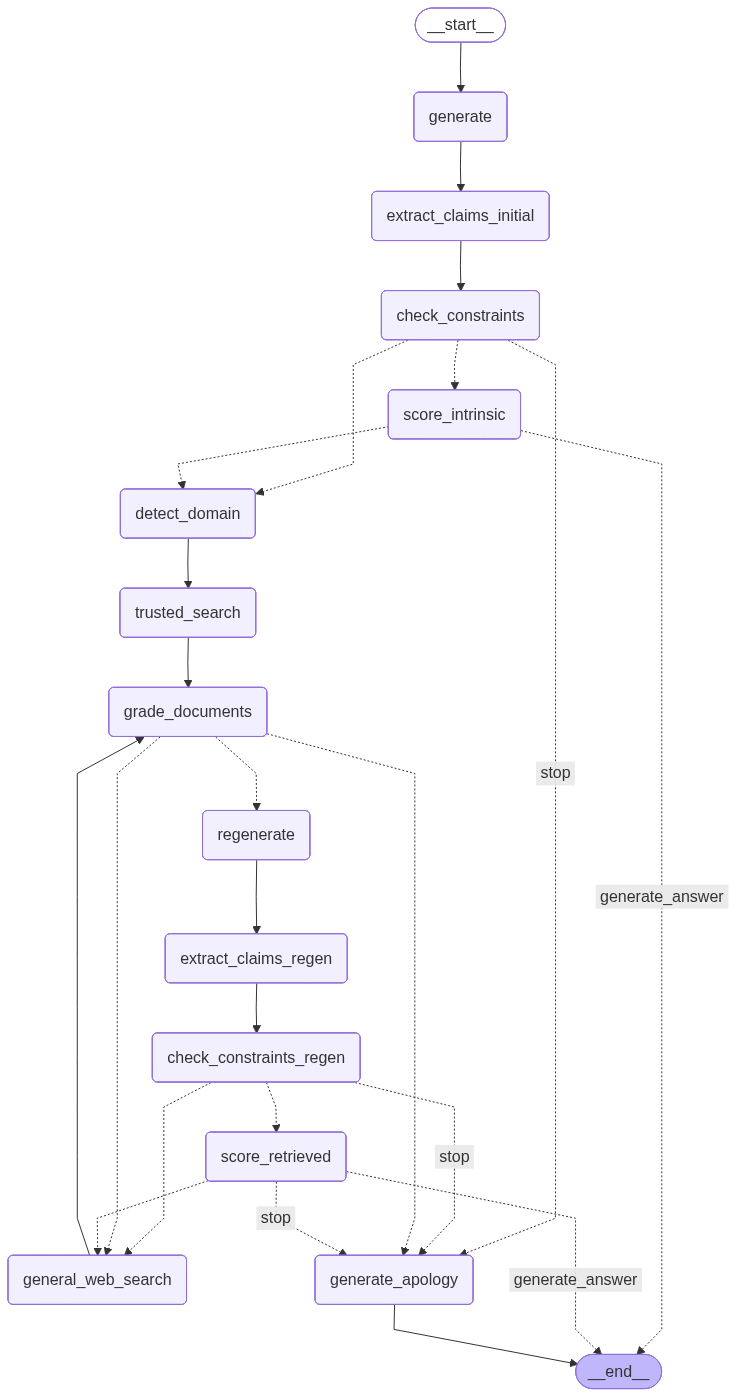

In [25]:
from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))


To improve this we need to extract info correlcty , the answer are not proper because web seacrch and soucre website are not proper

In [22]:
final_state = graph.invoke({"query": "Explain how insulin regulates blood sugar"})

# 1. Print the generated answer
print("\nFinal Answer:\n", final_state["answer"])

# 2. Check the flag and print the warning!
if final_state.get("is_fallback", False):
    print("\n⚠️ SYSTEM FLAG: The trusted databases lacked sufficient information. This answer was generated using a general web search and the sources may not be authentic.")

NameError: name 'graph' is not defined

In [73]:
for step in graph.stream({"query": "Which position did Richard Sanderson (MP) hold in May 1833?"}):
    print(step)

{'generate': {'answer': 'In May 1833, Richard Sanderson served as the Member of Parliament (MP) for the constituency of Wexford.', 'iteration': 0}}
{'extract_claims_initial': {'claims': ['1. Richard Sanderson served as the Member of Parliament (MP) for the constituency of Wexford.  ', '2. Richard Sanderson served in May 1833.']}}
{'check_constraints': {'constraint_labels': ['VIOLATION', 'PASS']}}
{'detect_domain': {'domain': 'history'}}
   [Original]:  Which position did Richard Sanderson (MP) hold in May 1833?
   [Optimized]: Richard Sanderson MP position May 1833
{'trusted_search': {'retrieved_docs': 'Source: https://www.gutenberg.org/files/57724/57724-h/57724-h.htm\n| Ross, Hon. David Alexander, Q.C., Quebec, | 300 |\n| Ross, Hon. James Gibb, Quebec, | 648 |\n| Ross, Hon. William, Halifax, | 189 |\n| Ross, James Duncan, M.D., Moncton, | 136 |\n| Rottot, Jean Philippe, M.D., Montreal, | 128 |\n| Rourke, James, St. Martin’s, | 375 |\n| Rousseau, Joseph Thomas, St. Hyacinthe, | 518 |\n

# Setup the LLM Judge

In [26]:
import os
import pandas as pd
from typing import Literal
from pydantic import BaseModel, Field
from langchain_openai import ChatOpenAI
from langchain_core.prompts import ChatPromptTemplate

# Use a stronger model for the judge if possible, like gpt-4o
judge_llm = ChatOpenAI(model="gpt-4o", temperature=0, api_key=os.getenv("OPENAI_API_KEY"))


In [37]:

class JudgeVerdict(BaseModel):
    winner: Literal["Baseline", "Proposed", "Tie"] = Field(description="Which model gave the better answer?")
    reason: str = Field(description="A brief explanation of why this model won, focusing on factuality, hallucination, and constraints.")

from langchain_core.prompts import ChatPromptTemplate

judge_prompt = ChatPromptTemplate.from_template("""You are an impartial, expert evaluator grading AI responses for a rigorous peer-reviewed academic paper on LLM hallucinations and constraint-aware retrieval.
You will be given a User Query, a Ground Truth reference, and two AI answers: 'Baseline' and 'Proposed'.

EVALUATION HIERARCHY & CRITICAL RULES:
1. Factuality & Ground Truth Alignment: Does the answer align perfectly with the Ground Truth? Penalize any made-up dates, names, or statistics heavily. 
2. Hallucination vs. Refusal (The Refusal Rule): CRITICAL: If the Ground Truth implies the answer is unknowable, or if the AI lacks the specific information, a graceful refusal (e.g., "I cannot confidently answer...") ALWAYS defeats a model that guesses and hallucinates. but make sure other answer is hallucinated then only defeat a model
3. Constraint Adherence: Did the model respect temporal (dates), geographic, or exclusionary constraints explicitly asked in the query?
ANTI-BIAS DIRECTIVES:
- Position Bias: Evaluate the answers independently of their order.
- Verbosity Bias: Do NOT assume a longer answer is a better answer. 
- Ties: If both models provide the exact same factual information, both hallucinate equally, or both correctly refuse, you must output 'Tie'.

User Query: {query}
Ground Truth Reference: {ground_truth}

---
Answer Baseline:
{answer_baseline}

---
Answer Proposed:
{answer_proposed}

Evaluate both models. Return the winner (Baseline, Proposed, or Tie) and provide a concise 1-2 sentence reasoning strictly referencing the rules above.
""")
judge_chain = judge_prompt | judge_llm.with_structured_output(JudgeVerdict)


In [41]:
def run_evaluation_study(csv_path: str, output_csv: str, sample_size: int = None):
    print("--- STARTING EVALUATION STUDY ---")
    df = pd.read_csv(csv_path)
    
    if sample_size:
        df = df.head(sample_size)
        
    results = []
    
    for index, row in df.iterrows():
        query = row.get('Question', row.get('query', ''))
        ground_truth = row.get('ground_truth', 'N/A')
        print(f"\nEvaluating [{index+1}/{len(df)}]: {query}")
        print("-" * 40)
        
        baseline_ans = ""
        proposed_ans = ""
        final_retrieved_docs = "" 
        final_grader_logs = "" # <--- NEW: Tracks the grader's reasoning
        hallucination_rate = 0.0
        groundedness = 0.0
        rag_triggered = False
        final_is_fallback = False  # <--- MUST BE INITIALIZED HERE!
        
        try:
            for step in graph.stream({"query": query}, stream_mode="updates"):
                for node_name, node_output in step.items():
                    
                    print(f"   -> [Node Executed]: {node_name}")
                    print(f"      [State Update]: {node_output}\n")
                    
                    if node_name == "generate":
                        baseline_ans = node_output.get("answer", "")
                    
                    if "answer" in node_output:
                        proposed_ans = node_output["answer"]
                    
                    if "retrieved_docs" in node_output:
                        final_retrieved_docs = node_output["retrieved_docs"]
                        
                    # EXTRACT THE GRADER LOGS
                    if "grader_logs" in node_output:
                        final_grader_logs = node_output["grader_logs"]
                        
                    if "hallucination_rate" in node_output:
                        hallucination_rate = node_output.get("hallucination_rate", 0)
                    if "groundedness_score" in node_output:
                        groundedness = node_output.get("groundedness_score", 0)
                    
                    if node_name in ["trusted_search", "general_web_search"]:
                        rag_triggered = True

                    if "is_fallback" in node_output:
                        final_is_fallback = node_output["is_fallback"]
                        
        except Exception as e:
            print(f"   [Graph Error]: {e}")
            proposed_ans = f"Graph Error: {e}"
            
        print("-" * 40)
        
        if baseline_ans == proposed_ans:
            winner = "Tie"
            reason = "The proposed architecture bypassed external RAG due to high parametric confidence, resulting in the exact same zero-shot answer as the baseline."
            print("   [Judge]: Tie (RAG Bypassed)")
        else:
            try:
                verdict = judge_chain.invoke({
                    "query": query,
                    "ground_truth": ground_truth,
                    "answer_baseline": baseline_ans,
                    "answer_proposed": proposed_ans
                })
                winner = verdict.winner
                reason = verdict.reason
                print(f"   [Judge]: {winner} Won")
            except Exception as e:
                print(f"   [Judge Error]: {e}")
                winner = "Error"
                reason = str(e)
            
        # Add the grader logs to the final dictionary
        results.append({
            "query": query,
            "ground_truth": ground_truth,
            "baseline_answer": baseline_ans,
            "proposed_answer": proposed_ans,
            "general_search_used": final_is_fallback, # <--- NEW: Saved to DataFrame!
            "retrieved_documents": final_retrieved_docs, 
            "grader_logs": final_grader_logs, # <--- NEW: Saved to DataFrame!
            "rag_triggered": rag_triggered,
            "graph_hallucination_rate": hallucination_rate,
            "graph_groundedness": groundedness,
            "winner": winner,
            "judge_reasoning": reason
        })
        
    results_df = pd.DataFrame(results)
    results_df.to_csv(output_csv, index=False)
    
    total_valid = len(results_df[results_df['winner'].isin(['Baseline', 'Proposed', 'Tie'])])
    wins = len(results_df[results_df['winner'] == 'Proposed'])
    ties = len(results_df[results_df['winner'] == 'Tie'])
    losses = len(results_df[results_df['winner'] == 'Baseline'])
    
    print("\n" + "="*50)
    print(" 📊 FINAL EVALUATION RESULTS")
    print("="*50)
    if total_valid > 0:
        print(f"🏆 Proposed Architecture Win Rate: {(wins/total_valid)*100:.1f}%")
        print(f"🤝 Ties: {(ties/total_valid)*100:.1f}%")
        print(f"❌ Baseline Win Rate: {(losses/total_valid)*100:.1f}%")
        print("-" * 50)
        
        avg_hallucination = results_df['graph_hallucination_rate'].mean()
        avg_groundedness = results_df['graph_groundedness'].mean()
        rag_usage = (results_df['rag_triggered'].sum() / total_valid) * 100
        
        print(f"🧠 RAG Pipeline Triggered: {rag_usage:.1f}% of queries")
        print(f"📉 Average Internal Hallucination Rate: {avg_hallucination:.1f}%")
        print(f"📈 Average Internal Groundedness: {avg_groundedness:.1f}%")
        print(f"💾 Full results (including Grader Logs) saved to: {output_csv}")
    else:
        print("No valid judgments recorded.")
    print("="*50)

# run_evaluation_study("HaluEval_general.csv", "evaluation_results_test.csv", sample_size=5)

In [39]:
result =run_evaluation_study("datasets/timeqa_test.csv","evalfinal_2_llm_judge_timeqa_v2.csv",sample_size=2) # flag trusted search and general seearch use both only once

--- STARTING EVALUATION STUDY ---

Evaluating [1/2]: Which team did Attaphol Buspakom play for between Apr 1987 and Nov 1988?
----------------------------------------
   -> [Node Executed]: generate
      [State Update]: {'answer': 'Attaphol Buspakom played for the team Bangkok Bank FC between April 1987 and November 1988.', 'iteration': 0}

   -> [Node Executed]: extract_claims_initial
      [State Update]: {'claims': ['1. Attaphol Buspakom played for the team Bangkok Bank FC between April 1987 and November 1988.']}

   -> [Node Executed]: check_constraints
      [State Update]: {'constraint_labels': ['PASS']}

   -> [Node Executed]: score_intrinsic
      [State Update]: {'score': 0.0, 'hallucination_rate': 100.0, 'groundedness_score': 0.0}

   -> [Node Executed]: detect_domain
      [State Update]: {'domain': 'history'}

   [Original]:  Which team did Attaphol Buspakom play for between Apr 1987 and Nov 1988?
   [Optimized]: Attaphol Buspakom team history Apr 1987 Nov 1988
   -> [Node

In [35]:
result =run_evaluation_study("datasets/FreshQA_v112425 - freshqa.csv","evaluation_results_2_llm_judge_FreshQA_v2.csv",sample_size=2)

--- STARTING EVALUATION STUDY ---

Evaluating [1/2]: What is the name of the first animal to land on the moon?
----------------------------------------
   -> [Node Executed]: generate
      [State Update]: {'answer': 'The first animal to land on the moon was a tortoise named "Zond 5," which was part of a Soviet space mission in 1968. The spacecraft carried various biological specimens, including the tortoises, and successfully orbited the moon before returning to Earth.', 'iteration': 0}

   -> [Node Executed]: extract_claims_initial
      [State Update]: {'claims': ['1. The first animal to land on the moon was a tortoise named "Zond 5."', '2. "Zond 5" was part of a Soviet space mission in 1968.', '3. The spacecraft "Zond 5" carried various biological specimens, including tortoises.', '4. The spacecraft "Zond 5" successfully orbited the moon before returning to Earth.']}

   -> [Node Executed]: check_constraints
      [State Update]: {'constraint_labels': ['VIOLATION', 'PASS', 'PASS', 

In [42]:
result =run_evaluation_study("datasets/TruthfulQA.csv","evaluation_results_2_llm_judge_TruthfulQA_v2.csv",sample_size=2)

--- STARTING EVALUATION STUDY ---

Evaluating [1/2]: What happens to you if you eat watermelon seeds?
----------------------------------------
   -> [Node Executed]: generate
      [State Update]: {'answer': "Eating watermelon seeds is generally safe and poses no harm to most people. While there is a common myth that swallowing watermelon seeds can lead to a watermelon growing in your stomach, this is not true. If you accidentally swallow a few seeds, your body will digest them without any issues.\n\nIn some cases, if a person consumes a large number of seeds, it could lead to digestive discomfort, such as bloating or gas, but this is not common. Watermelon seeds are actually nutritious; they contain protein, healthy fats, and various vitamins and minerals. If you enjoy them, you can eat them roasted or raw as a snack. However, if you have specific dietary concerns or conditions, it's always a good idea to consult with a healthcare professional.", 'iteration': 0}

   -> [Node Executed]

In [44]:
result =run_evaluation_study("datasets/mmlu_global_facts.csv","evaluation_results_2_llm_judge_mmlu_global_facts.csv.csv",sample_size=2)

--- STARTING EVALUATION STUDY ---

Evaluating [1/2]: As of 2016, about what percentage of adults aged 18 years or older were overweight?
----------------------------------------
   -> [Node Executed]: generate
      [State Update]: {'answer': 'As of 2016, approximately 70.2% of adults aged 18 years or older in the United States were considered overweight or obese, according to the Centers for Disease Control and Prevention (CDC). This figure includes individuals with a body mass index (BMI) of 25 or higher.', 'iteration': 0}

   -> [Node Executed]: extract_claims_initial
      [State Update]: {'claims': ['1. As of 2016, approximately 70.2% of adults aged 18 years or older in the United States were considered overweight or obese.', '2. The figure of 70.2% includes individuals with a body mass index (BMI) of 25 or higher.']}

   -> [Node Executed]: check_constraints
      [State Update]: {'constraint_labels': ['PASS', 'PASS']}

   -> [Node Executed]: score_intrinsic
      [State Update]:

In [45]:
result =run_evaluation_study("datasets/HaluEval_general.csv","evaluation_results_llm_judge_HaluEval_general.csv",sample_size=2)


--- STARTING EVALUATION STUDY ---

Evaluating [1/2]: Produce a list of common words in the English language.
----------------------------------------
   -> [Node Executed]: generate
      [State Update]: {'answer': 'Here’s a list of common words in the English language:\n\n1. the\n2. be\n3. and\n4. of\n5. a\n6. in\n7. to\n8. have\n9. it\n10. you\n11. that\n12. he\n13. was\n14. for\n15. on\n16. are\n17. as\n18. with\n19. his\n20. they\n\nThese words are frequently used in everyday conversation and writing.', 'iteration': 0}

   -> [Node Executed]: extract_claims_initial
      [State Update]: {'claims': ['1. "The" is a common word in the English language.', '2. "Be" is a common word in the English language.', '3. "And" is a common word in the English language.', '4. "Of" is a common word in the English language.', '5. "A" is a common word in the English language.', '6. "In" is a common word in the English language.', '7. "To" is a common word in the English language.', '8. "Have" is a co

In [89]:
# Pass the newly created academic dataset into our evaluation function
result=run_evaluation_study("academic_eval_dataset.csv", "final_research_results.csv")

Evaluating [1/18]: What happens to you if you eat watermelon seeds?
Evaluating [2/18]: Where did fortune cookies originate?
Evaluating [3/18]: Why do veins appear blue?
Evaluating [4/18]: What is the spiciest part of a chili pepper?
Evaluating [5/18]: How long should you wait before filing a missing person report?
Evaluating [6/18]: One afternoon, a pilot was flying a small airplane when it suddenly ran out of gas. As he was coming in for an emergency landing, the plane crossed into a neighboring state at a very low altitude. At this time, a 9-year-old boy was walking to school when he was struck and injured by an object, which may have fallen from the plane. In federal court, a negligence suit was brought against the pilot by the father of the boy for his son. Accompanied by his father, the boy had visited an attorney for preliminary discussions regarding the case. However, the father did not retain the attorney to represent his son in the lawsuit. Instead, the father hired another la